## Read scenes

In [1]:
from typing import Union, Literal
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import drjit as dr
import mitsuba as mi

from util import imshow_compare, imshow_compare_many

mi.set_variant('cuda_ad_rgb', 'llvm_ad_rgb')
print(f"{mi.variant() = }\n")

scene_dict = mi.cornell_box()
cbox_scene = mi.load_dict(scene_dict)
vmis_scene = mi.load_file("./scene/veach-bidir/scene_wo_delta.xml")
vmis_delta_scene = mi.load_file("./scene/veach-bidir/scene.xml")

scene_dict: dict[str, mi.Scene] = {'Cornell box': cbox_scene, 'Veach Bidir /wo Dirac Delta': vmis_scene, 'Veach Bidir w/ Dirac Delta': vmis_delta_scene}

# -------------------- Assertions --------------------
assert isinstance(cbox_scene, mi.Scene)
assert isinstance(vmis_scene, mi.Scene)
assert isinstance(vmis_delta_scene, mi.Scene)

jitc_llvm_init(): LLVM API initialization failed ..


mi.variant() = 'cuda_ad_rgb'



## Render GT

In [298]:
class ImageGT:
    def __init__(self, spp: int):
        assert isinstance(spp, int) and spp > 0
        self.img_dict = dict()
        self.spp = spp
        # self.last_spp = 0
        
        for label in scene_dict.keys():
            self.img_dict[label] = dict()
    
    # def render(self, depth: int, spp: int):
    #     assert isinstance(depth, int) and depth > 0, f"Invalid depth value: {depth = }"
    #     assert isinstance(spp, int) and spp > 0
    #     if spp <= self.last_spp:
    #         print(f"Images with {self.spp = } have already been stored.")
    #     else:
    #         for label, scene in scene_dict.items(): 
    #             self.img_dict[]

    def get(self,
            label: Literal["Cornell box", "Veach MIS", "Veach MIS w/ Dirac Delta"],
            depth: int
           ) -> mi.TensorXf:
        assert label in scene_dict, f"Key error: {label = }"
        assert isinstance(depth, int) and depth > 0, f"Invalid depth value: {depth = }"
        
        if not depth in self.img_dict[label]:
            integ: mi.Integrator = mi.load_dict({'type': 'path', 'max_depth': depth, 'rr_depth': depth})
            self.img_dict[label][depth] = mi.render(scene_dict[label], spp=self.spp,
                                                    integrator=integ)
            
        return self.img_dict[label][depth]
    
# Initialize
spp = 2048
imgGT = ImageGT(spp)

for depth in tqdm([1, 2, 4, 8]):
    for label in scene_dict:
        print(imgGT.get(label, depth).shape)

  0%|          | 0/4 [00:00<?, ?it/s]

(256, 256, 3)
(1024, 1024, 3)


 25%|██▌       | 1/4 [00:04<00:14,  4.69s/it]

(1024, 1024, 3)
(256, 256, 3)
(1024, 1024, 3)


 50%|█████     | 2/4 [00:15<00:16,  8.20s/it]

(1024, 1024, 3)
(256, 256, 3)
(1024, 1024, 3)


 75%|███████▌  | 3/4 [00:32<00:12, 12.44s/it]

(1024, 1024, 3)
(256, 256, 3)
(1024, 1024, 3)


100%|██████████| 4/4 [01:00<00:00, 15.01s/it]

(1024, 1024, 3)


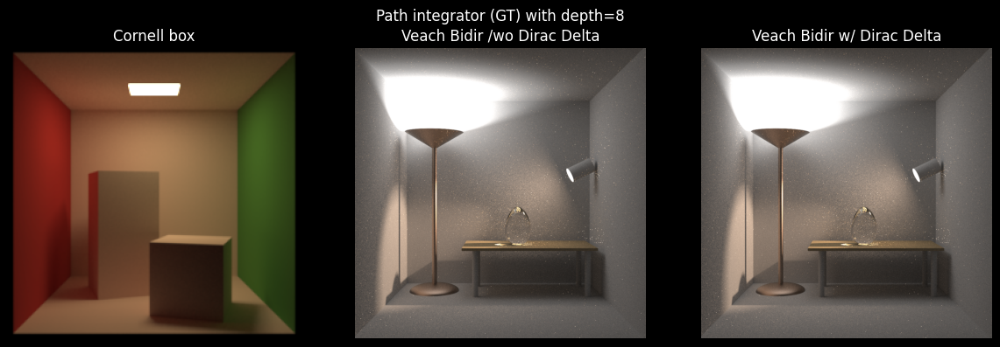

In [299]:
# -------------------- Parameters --------------------
figsize = (12, 4)
if False:
    spp = 256
depth = 8

# -------------------- Visualize --------------------
if False:
    integrator = mi.load_dict({'type': 'path', 'max_depth': depth, 'rr_depth': depth})
    img_gt_dict = dict()

fig, axes = plt.subplots(1, len(scene_dict), figsize=figsize)
# for ax, (label, scene) in zip(axes, scene_dict.items()):
for ax, label in zip(axes, scene_dict.keys()):
    if False:
        img = mi.render(scene, integrator=integrator, spp=spp)
        img_gt_dict[label] = img
    img_gt = imgGT.get(label, depth)
    ax.imshow(mi.Bitmap(dr.clip(img_gt, 0, 1)**(1/2.2)))
    ax.set_title(label)
    ax.set_axis_off()
fig.suptitle(f"Path integrator (GT) with {depth=}")
fig.tight_layout()

## 참고용 메모
If `ctx = mi.BSDFContext(mi.TransportMode.Radiance)` then:

`bsdf.eval(ctx, si, wo)`$= f_s($`wo`$, $`si.wi`$)\left|\hat n \cdot \hat \omega_i\right|$

If `ctx = mi.BSDFContext(mi.TransportMode.Importance)` then:

`bsdf.eval(ctx, si, wo)`$= f_s($`si.wi`$, $`wo`$)\left|\hat n \cdot \hat \omega_i\right|$

Reciprocal BRDF/BSDF = $f_s(\hat\omega_i,\hat\omega_o)=f_s(\hat\omega_o,\hat\omega_i)$

많이 사용되는 diffuse, dielectric, rough dielectric 등은 reciprocal BSDF임

## My BDPT
### Old version archive (commented out)

### Current version: Integrator

### Results

In [322]:
class PathIntegratorFinal(mi.ad.integrators.common.ADIntegrator):
    def __init__(self, props = mi.Properties()):
        super().__init__(props)
        self.max_caemradepth = int(props.get('max_cameradepth', 2))
        self.max_emitterdepth = int(props.get('max_emitterdepth', 2))
        self.light_image_buffer = None
        self.film_size = None
        self.sensor = None
        self.film = None
        self.size = None
        
    def prepare_buffer(self, scene):
        self.sensor :(mi.SensorPtr) = scene.sensors()[0]
        self.film = self.sensor.film()
        self.size = self.film.crop_size()
        self.film_size = mi.Vector2u(self.size.x, self.size.y)
        self.light_image_buffer = dr.zeros(mi.Float, self.size.x * self.size.y * 3)

    def sample(self,
               mode: dr.ADMode, # NOT USED NOW (differentiable rendering)
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               active: mi.Bool,
               **kwargs # Absorbs unused arguments
               ):
        
        ctx_c = mi.BSDFContext(mi.TransportMode.Radiance)
        ctx_e = mi.BSDFContext(mi.TransportMode.Importance) 
        
        L = mi.Spectrum(0.0)
        
        EPW : list[mi.Spectrum] = [mi.Spectrum(0.0) for _ in range(self.max_emitterdepth + 1)]
        EPS: list[mi.SurfaceInteraction3f] = [dr.zeros(mi.SurfaceInteraction3f) for _ in range(self.max_emitterdepth + 1)]
        EPA = [mi.Bool(False) for _ in range(self.max_emitterdepth + 1)]
        EPM = [dr.zeros(mi.Float) for _ in range(self.max_emitterdepth + 1)]
        
        emitter_weight = dr.zeros(mi.Spectrum)
        si = dr.zeros(mi.SurfaceInteraction3f)
        
        emitter_idx, emitter_idx_weight, _ = scene.sample_emitter(sampler.next_1d(), active)
        emitter = dr.gather(mi.EmitterPtr, scene.emitters_dr(), emitter_idx)
        
        is_infinite = mi.has_flag(emitter.flags(), mi.EmitterFlags.Infinite)
        is_delta = mi.has_flag(emitter.flags(), mi.EmitterFlags.Delta)
        
        active_e = active & ~is_infinite & ~is_delta
        ps, pos_weight = emitter.sample_position(0.0, sampler.next_2d(), active_e)
        
        emitter_weight[active_e] = pos_weight*emitter_idx_weight
        
        si.p[active_e] = ps.p
        si.n[active_e] = ps.n
        si.uv[active_e] = ps.uv
        si.time[active_e] = ps.time
        si.sh_frame[active_e] = mi.Frame3f(ps.n)
        
        wo_local = mi.warp.square_to_cosine_hemisphere(sampler.next_2d())
        
        wavelenghts, wavelenghts_weight = emitter.sample_wavelengths(si, sampler.next_1d(), active_e)
        si.wavelengths = wavelenghts
        
        si.wi[active_e] = wo_local
        wo_world = si.to_world(wo_local)
        
        EPW[0] = emitter_weight
        EPS[0] = si
        EPA[0] = active_e
        EPM[0] = 0.0
        
        pdf_emit = ps.pdf/emitter_idx_weight
        
        emitter_ray = si.spawn_ray(wo_world)
        
        
        pdf_dir = mi.warp.square_to_cosine_hemisphere_pdf(wo_local)
        safe_pdf_dir = dr.maximum(1e-6, pdf_dir)
        
        Le = emitter.eval(si, active_e)
        
        path_weight = emitter_weight  * wavelenghts_weight * dr.pi # 
        path_weight = dr.select(active_e, path_weight, 0.0)
        
        prev_pdf_fwd = safe_pdf_dir*pdf_emit
        prev_n = si.n
        
        for i in range(self.max_emitterdepth):
            
            si = scene.ray_intersect(emitter_ray)
            active_e &= si.is_valid()
            
            _, pdf_rev = si.bsdf().eval_pdf(ctx_e, si, si.to_local(-emitter_ray.d), active_e)
            
            cos_curr = dr.maximum(0.0, dr.dot(si.n, -emitter_ray.d))
            cos_prev = dr.maximum(0.0, dr.dot(prev_n, emitter_ray.d))
            
            denom = prev_pdf_fwd * cos_curr
            numer = pdf_rev * cos_prev
            
            mis_ratio = dr.select(denom > 1e-6, numer / denom, 0.0)
            #mis_ratio *= mis_ratio
            
            idx = i + 1
            
            EPM[idx] = mis_ratio * (1.0 + EPM[i])
            EPS[idx] = si
            EPW[idx] = path_weight
            EPA[idx] = active_e
            
            bsdf_sample, bsdf_weight = si.bsdf().sample(ctx_e, si, sampler.next_1d(), sampler.next_2d(), active_e)
            path_weight *= bsdf_weight
            
            prev_pdf_fwd = bsdf_sample.pdf
            prev_n = si.n
            emitter_ray = si.spawn_ray(si.to_world(bsdf_sample.wo))
            
            
        mis0 = mi.Float(1.0)
            
        for j in range(1, self.max_emitterdepth+1): # connect c0 - li - .. - l0
            si_e = EPS[j]
            weight_e = EPW[j]
            active_e_node = EPA[j]
            mis_light = EPM[j]
            
            #is_delta_emit = mi.Bool(False)
            #if j > 0:
            #    is_delta_emit = mi.has_flag(si_e.bsdf().flags(), mi.BSDFFlags.Delta)
                
            ds, sensor_val = self.sensor.sample_direction(si_e, sampler.next_2d(), active_e_node)
            active_conn = active_e_node  & (ds.pdf > 0.0) #&~is_delta_emit
             
            shadow_ray = si_e.spawn_ray_to(ds.p)
            active_conn &= ~scene.ray_test(shadow_ray)
            
            d_vec = ds.d
            dist_sq = ds.dist * ds.dist
            dist_sq = dr.maximum(dist_sq, 1e-3)
            
            cos_e = dr.abs(dr.dot(si_e.n, d_vec))
            cos_c = dr.abs(dr.dot(ds.n, -d_vec))
            
            #active_conn &= (cos_e > 0.0) & (cos_c > 0.0)
            
            pdf_sensor_solid = ds.pdf
            pdf_cam_area = dr.select(dist_sq > 1e-6, pdf_sensor_solid * dr.abs(cos_c) / dist_sq, 0.0)
            
            #p_l2c = dr.select(dist_sq > 1e-6, ds.pdf * dr.abs(cos_c) / dist_sq, 0.0)
            
            pdf_light_solid = mi.Float(1.0)
            pdf_light_area = mi.Float(1.0)
            
            wo_local = si_e.to_local(d_vec)
            if j == 0:
                #   Emitter 자체인 경우 (Cosine 분포)
                pdf_light_solid = mi.warp.square_to_cosine_hemisphere_pdf(wo_local)
                pdf_light_area = dr.select(dist_sq > 1e-6, pdf_light_solid * dr.abs(cos_c) / dist_sq, 0.0)
                pdf_light_area *= pdf_emit #dr.select(dist_sq > 1e-6, pdf_light_solid * dr.abs(cos_c) / dist_sq, 0.0)
            else:
                # 표면 반사인 경우 (BSDF 확률)
                
                _, pdf_light_solid = si_e.bsdf().eval_pdf(ctx_e, si_e, wo_local, active_conn)
                pdf_light_area = dr.select(dist_sq > 1e-6, pdf_light_solid * dr.abs(cos_c) / dist_sq, 0.0)
            
            connectpdf = (pdf_light_area/pdf_cam_area)
            #connectpdf *= connectpdf
            
            ratio_cam_vs_light = dr.select(pdf_light_area > 1e-6, mis_light * connectpdf, 0.0)
            
            mis_weight = 1.0 / (1.0 + ratio_cam_vs_light)
            mis_weight = dr.select(active_conn, mis_weight, 0.0)
            mis_weight = dr.select(dr.isfinite(mis_weight), mis_weight, 0.0)
                     
            L_connect = mi.Spectrum(0.0)
            
            
            if(j == 0):
                si_e.wi = si_e.to_local(-wo_local)
                Le = emitter.eval(si_e, active_conn)
                L_connect = weight_e * sensor_val * Le * cos_e
            else:
                bsdf_val = si_e.bsdf().eval(ctx_e, si_e, wo_local, active_conn)
                L_connect = weight_e  * sensor_val * bsdf_val#* bsdf_val
                
            L_connect = dr.clip(L_connect, 0.0, 1000.0)
                
            L_connect = dr.select(active_conn, L_connect * mis_weight, 0.0)
            
            if(j ==0 ):
                mis0 -= mis_weight
            
            width_f = mi.Float(self.film_size.x)
            height_f = mi.Float(self.film_size.y)
            
            pos_x = dr.clip(dr.floor(ds.uv.x), 0.0, width_f - 1.0)
            pos_y = dr.clip(dr.floor(ds.uv.y), 0.0, height_f - 1.0)
                
            pixel_idx = (mi.UInt32(pos_y) * self.film_size.x + mi.UInt32(pos_x)) * 3
            

            dr.scatter_add(target=self.light_image_buffer, value=L_connect[0], index=pixel_idx + 0, active=active_conn)
            dr.scatter_add(target=self.light_image_buffer, value=L_connect[1], index=pixel_idx + 1, active=active_conn)
            dr.scatter_add(target=self.light_image_buffer, value=L_connect[2], index=pixel_idx + 2, active=active_conn)
            
        
        beta_c = mi.Spectrum(1.0)
        active_c = active
        mis_cam = mi.Float(0.0)
        prev_pdf_fwd_c = mi.Float(0.0)
        prev_n_c = dr.zeros(mi.Vector3f)
        prev_si = dr.zeros(mi.SurfaceInteraction3f)
        
        prev_bsdf_delta =  mi.Bool(True)
        
        si = scene.ray_intersect(ray)
        Le_direct = si.emitter(scene).eval(si)
        
        L += beta_c * Le_direct # connect c0 - c1
        
        prev_pdf_fwd_c = mi.Float(1.0) #mi.warp.square_to_cosine_hemisphere_pdf(-si.wi)
        
        for i in range(self.max_caemradepth):
            si = scene.ray_intersect(ray)
            active_c &= si.is_valid()
            
            bsdf = si.bsdf()
            
            if i > 0:
                ds = mi.DirectionSample3f(scene, si=si, ref=prev_si)
                pdf_nee = scene.pdf_emitter_direction(prev_si, ds, ~prev_bsdf_delta)
                
                hit_emitter_ptr = si.emitter(scene)
                
                w_nee = dr.select(prev_pdf_fwd_c > 1e-6, pdf_nee / prev_pdf_fwd_c, 0.0)
                
                denom_w = 1.0 + w_nee*(1.0 + mis_cam)
                
                mis_weight_bsdf = dr.select(denom_w > 1e-6, 1 / denom_w, 0.0)
                mis_weight_bsdf = dr.select(dr.isfinite(mis_weight_bsdf), mis_weight_bsdf, 0.0)
                
                Le_bsdf_hit = hit_emitter_ptr.eval(si, active_c)
                Le_bsdf_hit = dr.clip(Le_bsdf_hit, 0.0, 1000.0)
                L += beta_c * Le_bsdf_hit * mis_weight_bsdf # connect c0 - c1 - c(i+1)
            
            cos_curr = dr.maximum(0.0, dr.dot(si.sh_frame.n, -ray.d))
            cos_prev = dr.maximum(0.0, dr.dot(prev_n_c, ray.d))
            _, pdf_rev_c = si.bsdf().eval_pdf(ctx_c, si, si.to_local(-ray.d), ~prev_bsdf_delta)
                
                
            denom_c = prev_pdf_fwd_c * cos_curr
            numer_c = pdf_rev_c * cos_prev
            ratio = dr.select(denom_c > 1e-6, numer_c / denom_c, 0.0)
            #ratio *= ratio   
            mis_cam = ratio * (1.0 + mis_cam)
            
            for j in range(self.max_emitterdepth + 1):
                si_e = EPS[j]
                weight_e = EPW[j]
                active_e_node = EPA[j]
                
                active_conn = active_c & active_e_node
                
                d_conn = si_e.p - si.p
                dist_sq = dr.squared_norm(d_conn)
                dist_sq = dr.maximum(dist_sq, 1e-3)
                dist = dr.sqrt(dist_sq)
                wo_c = d_conn / dist
                wo_e = -wo_c
                
                shadow_ray = si.spawn_ray_to(si_e.p)
                
                is_delta_cam = mi.has_flag(bsdf.flags(), mi.BSDFFlags.Delta)
                is_delta_emit = mi.Bool(False)
                if j > 0:
                    is_delta_emit = mi.has_flag(si_e.bsdf().flags(), mi.BSDFFlags.Delta)
                
                visible = active_conn & ~scene.ray_test(shadow_ray) & ~is_delta_cam & ~is_delta_emit
                
                cos_c = dr.dot(si.n, wo_c)
                cos_e = dr.dot(si_e.n, wo_e)
                
                _, pdf_c2l = bsdf.eval_pdf(ctx_c, si, si.to_local(wo_c), visible)
                p_A_c2l = pdf_c2l * dr.abs(cos_e) / dist_sq
                
                p_A_l2c = mi.Float(0.0)
                
                if j == 0:
                    p_A_l2c = pdf_emit #dr.select(weight_e > 1e-6, 1.0 / weight_e, 0.0)
                    #pdf_dir = mi.warp.square_to_cosine_hemisphere_pdf(wo_e) * dr.abs(cos_c) / dist_sq
                    #p_A_l2c *= pdf_dir
                else:
                    _, pdf_l2c_solid = si_e.bsdf().eval_pdf(ctx_e, si_e, si_e.to_local(wo_e), visible)
                    p_A_l2c = pdf_l2c_solid * dr.abs(cos_c) / dist_sq

                
                cam_side = p_A_c2l / p_A_l2c
                #cam_side *= cam_side
                
                light_side = p_A_l2c / p_A_c2l
                #light_side *= light_side
                
                w_cam_side = dr.select(p_A_l2c > 1e-6, (mis_cam) * (cam_side), 0.0)
                w_light_side = dr.select(p_A_c2l > 1e-6, EPM[j] * (light_side), 0.0)
                
                mis_weight = 1.0 / (1.0 + w_cam_side + w_light_side)
                mis_weight = dr.select(visible, mis_weight, 0.0)
                mis_weight = dr.select(dr.isfinite(mis_weight), mis_weight, 0.0)
                
                
                contrib = mi.Spectrum(0.0)
                
                if j == 0:
                    si_e.wi = si_e.to_local(wo_e)
                    Le_connect = emitter.eval(si_e, visible)
                    
                    f_cam = bsdf.eval(ctx_c, si, si.to_local(wo_c), visible)
                    G = dr.abs(cos_e) / dist_sq
                    contrib = beta_c  * Le_connect * weight_e * G * f_cam
                    
                else:
                    f_cam = bsdf.eval(ctx_c, si, si.to_local(wo_c), visible)
                    f_emit = si_e.bsdf().eval(ctx_e, si_e, si_e.to_local(wo_e), visible)
                    G = 1.0 / dist_sq
                    contrib = beta_c * f_cam * G * f_emit * weight_e 

                mis_weight = dr.select(dr.isfinite(mis_weight), mis_weight, 0.0)
                contrib = dr.clip(contrib, 0.0, 1000.0)
                L += dr.select(visible, contrib*mis_weight, 0.0) # connect c0 - c1 - c(i+1) - l(j) - l(0)


            bsdf_sample, bsdf_weight = bsdf.sample(ctx_c, si, sampler.next_1d(), sampler.next_2d(), active_c)
            prev_pdf_fwd_c = bsdf_sample.pdf
            prev_n_c = si.sh_frame.n
            prev_si = si
            beta_c *= bsdf_weight
            prev_bsdf_delta = mi.has_flag(bsdf_sample.sampled_type, mi.BSDFFlags.Delta)
            ray = si.spawn_ray(si.to_world(bsdf_sample.wo))
            
        
        
        return L, active, [], None

In [323]:
mi.register_integrator("mypath", lambda props: PathIntegratorFinal(props))

In [328]:
# ---------- Parameters ----------
spp = 2048
depth_sensor = 6
depth_emitter = 4



props = mi.Properties()
props['max_cameradepth'] = depth_sensor
props['max_emitterdepth'] = depth_emitter

mypath = PathIntegratorFinal(props)

img_ours_dict = {}
for label, scene in scene_dict.items():
    mypath.prepare_buffer(scene)
    img = mi.render(scene, integrator=mypath, spp=spp)
    dr.eval(mypath.light_image_buffer)
    sensor = mypath.sensor
    film_size = sensor.film().crop_size()
    light_buffer_flat = mypath.light_image_buffer
    img_light = mi.TensorXf(light_buffer_flat, shape=(film_size.y, film_size.x, 3))
    final_img = img + (img_light / spp)
    img_ours_dict[label] = final_img


#mypath = mi.load_dict({'type': "mypath", 'max_depth': 6})


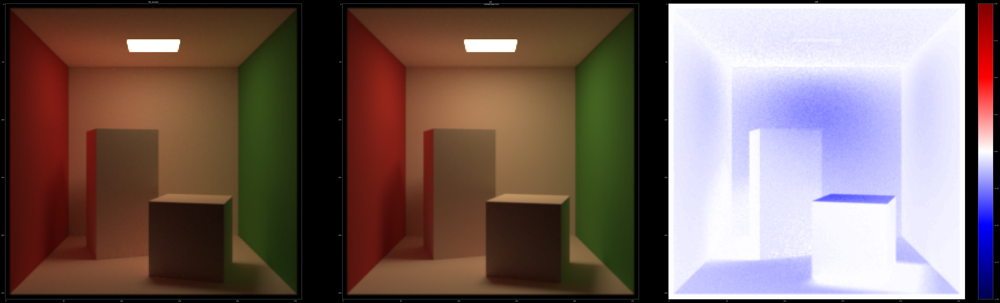

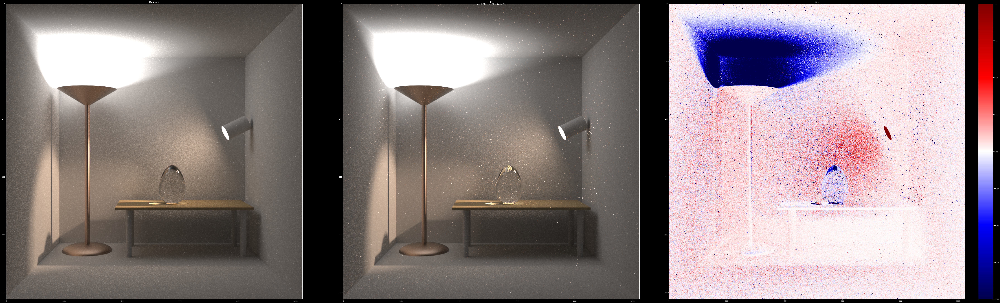

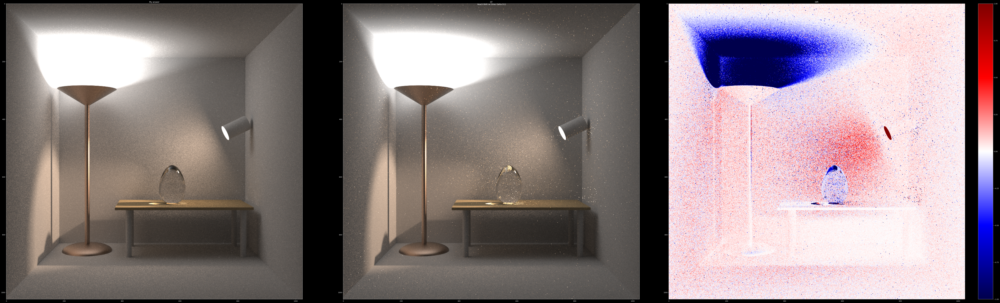

In [329]:
for label in scene_dict:
    depth_total = depth_sensor + depth_emitter + 1
    title = f"{label} D{depth_total}"
    imshow_compare(img_ours_dict[label].numpy(), imgGT.get(label, depth_total).numpy(),
                   figsize=(90, 27), suptitle=title, vabs=1.0)